In [1298]:
import numpy as np
import pandas as pd

from sklearn.datasets import (load_diabetes,load_breast_cancer,load_digits,load_iris)
from sklearn.model_selection import train_test_split
from sklearn.metrics import (mean_squared_error,r2_score,accuracy_score,confusion_matrix,precision_recall_fscore_support)

In [1299]:
# 1. Diabetes dataset
diabetes = load_diabetes(scaled=False)
X_diabetes = diabetes.data
y_diabetes = diabetes.target

# 2. Breast Cancer dataset
breast_cancer = load_breast_cancer()
X_breast = breast_cancer.data
y_breast = 1 - breast_cancer.target

# 3. Digits dataset
digits = load_digits()
X_digits = digits.data / 16.0
y_digits = digits.target

# 4. Iris dataset
iris = load_iris()
X_iris = iris.data
y_iris = iris.target


In [1300]:
def split_dataset(X, y, classification=True):

    #20% for testing
    stratify_value = y if classification else None
    
    X_temp, X_test, y_temp, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42,
        stratify=stratify_value)


    #25% of the remaining 80% for validation
    stratify_value = y_temp if classification else None

    X_train, X_val, y_train, y_val = train_test_split(
        X_temp,
        y_temp,
        test_size=0.25,
        random_state=42,
        stratify=stratify_value)

    return X_train, X_val, X_test, y_train, y_val, y_test


diabetes_split = split_dataset(X_diabetes, y_diabetes, classification=False)
breast_split = split_dataset(X_breast, y_breast)
digits_split = split_dataset(X_digits, y_digits)
iris_split = split_dataset(X_iris, y_iris)


In [1301]:
datasets = {
    "Diabetes": diabetes_split,
    "Breast Cancer": breast_split,
    "Digits": digits_split,
    "Iris": iris_split
}

for name, split in datasets.items():

    X_train, X_val, X_test, y_train, y_val, y_test = split

    print("\n", name)

    print("Training size:", len(X_train))
    print("Validation size:", len(X_val))
    print("Testing size:", len(X_test))
    print("Total size:", len(X_train) + len(X_val) + len(X_test))

    if name != "Diabetes":
        print("\nTraining class counts:",
              np.unique(y_train, return_counts=True))

        print("Validation class counts:",
              np.unique(y_val, return_counts=True))

        print("Testing class counts:",
              np.unique(y_test, return_counts=True))




 Diabetes
Training size: 264
Validation size: 89
Testing size: 89
Total size: 442

 Breast Cancer
Training size: 341
Validation size: 114
Testing size: 114
Total size: 569

Training class counts: (array([0, 1]), array([214, 127]))
Validation class counts: (array([0, 1]), array([71, 43]))
Testing class counts: (array([0, 1]), array([72, 42]))

 Digits
Training size: 1077
Validation size: 360
Testing size: 360
Total size: 1797

Training class counts: (array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), array([106, 109, 107, 109, 109, 109, 109, 107, 104, 108]))
Validation class counts: (array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), array([36, 37, 35, 37, 36, 36, 36, 36, 35, 36]))
Testing class counts: (array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), array([36, 36, 35, 37, 36, 37, 36, 36, 35, 36]))

 Iris
Training size: 90
Validation size: 30
Testing size: 30
Total size: 150

Training class counts: (array([0, 1, 2]), array([30, 30, 30]))
Validation class counts: (array([0, 1, 2]), array([10, 10, 10]))
Testing class c

In [1302]:
class Standardizer:

    def fit(self, X):
        self.mean = np.mean(X, axis=0)
        self.std = np.std(X, axis=0)
        self.std[self.std == 0] = 1  #avoid devision by 0
        return self

    def transform(self, X):
        return (X - self.mean) / self.std

    

In [1303]:
def add_bias(X):
        # Add a column of ones at the beginning
        return np.column_stack((np.ones(X.shape[0]), X))

In [1304]:
X_train, X_val, X_test, y_train, y_val, y_test = diabetes_split

scaler = Standardizer()
scaler.fit(X_train)

X_train_std = scaler.transform(X_train)
X_val_std = scaler.transform(X_val)
X_test_std = scaler.transform(X_test)

print("Training means:")
print(np.mean(X_train_std, axis=0))

print("\nTraining standard deviations:")
print(np.std(X_train_std, axis=0))

X_train_bias = add_bias(X_train_std)

print("\nShape before adding bias:", X_train_std.shape)
print("Shape after adding bias:", X_train_bias.shape)


Training means:
[-2.26249995e-16  1.79990702e-16 -2.23726761e-15 -3.61663561e-16
 -5.88754634e-17 -1.08348348e-17  1.94394164e-16 -4.03717464e-17
  2.03877319e-15 -5.53100810e-16]

Training standard deviations:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]

Shape before adding bias: (264, 10)
Shape after adding bias: (264, 11)


In [1305]:
def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))

def r2(y_true, y_pred):

    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_total = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - (ss_res / ss_total)

In [1306]:
def confusion_matrix(y, pred, K):
    cm = np.zeros((K, K), dtype=int)
    np.add.at(cm, (y, pred), 1)
    return cm

In [1307]:
def accuracy(y, pred):
    return np.mean(y == pred)


def classification_metrics(cm):

    tp = np.diag(cm)
    fp = np.sum(cm, axis=0) - tp
    fn = np.sum(cm, axis=1) - tp

    precision = np.divide(
        tp,
        tp + fp,
        out=np.zeros_like(tp, dtype=float),
        where=(tp + fp) != 0
    )

    recall = np.divide(
        tp,
        tp + fn,
        out=np.zeros_like(tp, dtype=float),
        where=(tp + fn) != 0
    )

    f1 = np.divide(
        2 * precision * recall,
        precision + recall,
        out=np.zeros_like(precision, dtype=float),
        where=(precision + recall) != 0
    )

    macro_precision = np.mean(precision)
    macro_recall = np.mean(recall)
    macro_f1 = np.mean(f1)

    return {
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "macro_precision": macro_precision,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1
    }

In [1308]:
X_tr, X_va, X_te, y_tr, y_va, y_te = breast_split

scaler = Standardizer()
scaler.fit(X_tr)
X_tr_std=scaler.transform(X_tr)
X_va_std=scaler.transform(X_va)
X_te_std=scaler.transform(X_te)
X_tr_bias=add_bias(X_tr_std)
X_va_bias=add_bias(X_va_std)
X_te_bias=add_bias(X_te_std)
N = len(y_tr)
print("Training shape without bias:", X_tr.shape)
print("Validation shape without bias:", X_va.shape)
print("Testing shape without bias:", X_te.shape)
print("Training shape with bias:", X_tr_bias.shape)
print("Validation shape with bias:", X_va_bias.shape)
print("Testing shape with bias:", X_te_bias.shape)
# print("Number of training samples:", N)
# print("Number of validation samples:", len(y_va))
# print("Number of testing samples:", len(y_te))
print("Labels:", np.unique(y_tr))
# print("Labels:", np.unique(y_va))
# print("Labels:", np.unique(y_te))
print(breast_cancer.feature_names)


Training shape without bias: (341, 30)
Validation shape without bias: (114, 30)
Testing shape without bias: (114, 30)
Training shape with bias: (341, 31)
Validation shape with bias: (114, 31)
Testing shape with bias: (114, 31)
Labels: [0 1]
['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']


In [1309]:
def naive_sigmoid(z):
    return 1/(1+np.exp(-z))


def naive_loss(z,y):
    p=naive_sigmoid(z)
    return -(y*np.log(p)+(1-y)*np.log(1-p))

-"Derive ∇J = (1/N) X̃T(p − y) + λ[0, w1:] using σ′(z) = σ(z)(1 − σ(z))":

li=−[yi*log(pi)+(1−yi)*log(1−pi)]
pi=σ(zi)
zi=wT*X̃i

Differentiate the loss with respect to its probability
∂l/∂pi= -yi/pi +(1-yi)/(1-pi)
= (-yi(1-pi)+pi(1-yi))/(pi*(1-pi))
=  (-yi+yipi+pi-piyi)/(pi*(1-pi))
= (-yi+pi)/(pi*(1-pi))

Differentiate the pi with respect to its zi
σ′(zi) = σ(zi)(1 − σ(zi))= pi(1-pi)

Differentiate the loss with respect to its zi
∂l/∂zi= ∂l/∂pi*∂pi/∂zi
= ((-yi+pi)/(pi*(1-pi)))*pi(1-pi)
=(-yi+pi)

Differentiate the zi with respect to its w
∂zi/∂w=X̃i

Differentiate the loss with respect to its w
∂l/∂w=∂l/∂zi*∂zi/∂w=(-yi+pi)*X̃i
=(pi-yi)*X̃i

∇J =(1/N)X̃T(p − y)+λ[0, w1:]


-"show that the per-sample loss equals log(1+e^z) − y·z."

l=−[y*log(p)+(1−y)*log(1−p)]
p=σ(z)=1/1+e^-z

so
log(p)=log(1/1+e^-z)
=log((1+e^-z)^-1)
=-log(1+e^-z)

1-p=e^-z/1+e^-z
log(1-p)=log(e^-z/1+e^-z)
=log(e^-z)-log(1+e^-z)
=-zlog(e)-log(1+e^-z)
=-z-log(1+e^-z)

Substitute into the loss:
l=ylog(1+e^-z)+(1-y)z+(1-y)log(1+e^-z)
=log(1+e^-z)+(1-y)z         (eqn 1)

log(1+e^-z)= log(e^-z(1+e^z))
=-zlog(e)+log(1+e^z)
=-z+log(1+e^z)

back to (eqn 1)
-z+log(1+e^z)+(1-y)z 
log(1+e^z)-yz

In [1310]:
def sigmoid(z):
    z=np.asarray(z,float) #convert z into a NumPy array of floats to perform operations such as: exp
    p=np.empty(z.shape)
    positive=z>=0
    negative =z<0
    p[positive]=1/(1+np.exp(-z[positive]))
    p[negative]=np.exp(z[negative])/(np.exp(z[negative])+1)
    return p

def stable_loss(z,y):
    return np.logaddexp(0,z)-y*z

In [1311]:
for z in [800,-800]:
    for y in [0, 1]:
        print("z =",z,"y =",y)
        print("Naive sigmoid:",naive_sigmoid(z))
        print("Stable sigmoid:",sigmoid(z))
        print("Naive loss:",naive_loss(z,y))
        print("Stable loss:",stable_loss(z,y))
        print("\n")

z = 800 y = 0
Naive sigmoid: 1.0
Stable sigmoid: 1.0
Naive loss: inf
Stable loss: 800.0


z = 800 y = 1
Naive sigmoid: 1.0
Stable sigmoid: 1.0
Naive loss: nan
Stable loss: 0.0


z = -800 y = 0
Naive sigmoid: 0.0
Stable sigmoid: 0.0
Naive loss: nan
Stable loss: 0.0


z = -800 y = 1
Naive sigmoid: 0.0
Stable sigmoid: 0.0
Naive loss: inf
Stable loss: 800.0




C:\Users\malak\AppData\Local\Temp\ipykernel_19524\2679163861.py:7: RuntimeWarning: divide by zero encountered in log
  return -(y*np.log(p)+(1-y)*np.log(1-p))
C:\Users\malak\AppData\Local\Temp\ipykernel_19524\2679163861.py:7: RuntimeWarning: invalid value encountered in scalar multiply
  return -(y*np.log(p)+(1-y)*np.log(1-p))
C:\Users\malak\AppData\Local\Temp\ipykernel_19524\2679163861.py:2: RuntimeWarning: overflow encountered in exp
  return 1/(1+np.exp(-z))


The stable sigmoid and stable loss function avoid overflow and invalid values for very large positive and negative inputs. Unlike the naive implementation, the stable loss produces finite results for z=800 and z=-800.

In [1312]:
def compute_loss(X,y,w,lam):
    z=X@w
    dataloss =np.mean(stable_loss(z, y))
    regularization =(lam/2)*np.sum(w[1:]**2)
    return dataloss+regularization


In [1313]:
def compute_gradient(X, y, w, lam):
    N=len(y)  #We divide by N later because we calculate the average gradient.
    z=X@w
    p=sigmoid(z)
    gradient=(X.T@(p-y))/N
    gradient[1:]+=lam*w[1:]
    return gradient

In [1314]:
def numerical_gradient(X,y,w,lam,eps=1e-5):
    grad = np.zeros(w.shape)
    for i in range(len(w)):
        wplus=w.copy()
        wminus=w.copy()
        wplus[i]+=eps
        wminus[i]-=eps
        lossplus=compute_loss(X,y,wplus,lam)
        lossminus=compute_loss(X,y,wminus,lam)
        grad[i]=(lossplus-lossminus)/(2*eps)
    return grad

In [1315]:
def grad_check(X,y,w,lam):
    analytical=compute_gradient(X,y,w,lam)
    numerical=numerical_gradient(X,y,w,lam)
    numerator=np.linalg.norm(analytical-numerical)
    denominator =max(np.linalg.norm(analytical),np.linalg.norm(numerical),1e-12)
    relativeerror=numerator/denominator
    print("Analytical gradient:",analytical)
    print("Numerical gradient:",numerical)
    print("Relative error:",relativeerror)
    if relativeerror<1e-6:
        print("Passed, relative error < 1e-6")
    else:
        print("Failed")
    return relativeerror

In [1316]:
rng=np.random.default_rng(42)
Xgrad= X_tr_bias
ygrad= y_tr
wgrad=rng.normal(0,0.1,Xgrad.shape[1])
relativeerror=grad_check(Xgrad,ygrad,wgrad,0.1)

Analytical gradient: [ 0.13414723 -0.37954189 -0.15402953 -0.36188413 -0.37823269 -0.17928092
 -0.2534387  -0.31801328 -0.36982638 -0.16484042  0.07235882 -0.26471545
  0.0230674  -0.25061787 -0.26423808  0.00639891 -0.09887254 -0.11266527
 -0.18337334  0.00194591 -0.00501694 -0.38675424 -0.17156898 -0.3799604
 -0.36266334 -0.17711743 -0.223743   -0.26237071 -0.35577764 -0.17064627
 -0.06359304]
Numerical gradient: [ 0.13414723 -0.37954189 -0.15402953 -0.36188413 -0.37823269 -0.17928092
 -0.2534387  -0.31801328 -0.36982638 -0.16484042  0.07235882 -0.26471545
  0.0230674  -0.25061787 -0.26423808  0.00639891 -0.09887254 -0.11266527
 -0.18337334  0.00194591 -0.00501694 -0.38675424 -0.17156898 -0.3799604
 -0.36266334 -0.17711743 -0.223743   -0.26237071 -0.35577764 -0.17064627
 -0.06359304]
Relative error: 1.7775135713047355e-11
Passed, relative error < 1e-6


The analytical gradient closely matches the numerical gradient. The relative error is less than (1e-6), verifying that the implemented gradient is correct.

"at a random point w ~ N(0, 0.1^2)" means
N: normal distribution,
0: mean,
0.1^2:variance, so the standard deviation is 0.1

In [1317]:
def compute_data_loss(X,y,w):
    z=X@w
    return np.mean(stable_loss(z, y))

In [1318]:
def train_model(X_train, y_train, X_val, y_val, lam, eta, epochs):
    w=np.zeros(X_train.shape[1])
    old={"trainloss": [],"valloss": [],"trainaccuracy": [],"valaccuracy": []} 
    #Because we want to record what happens after every epoch.
    for epoch in range(epochs):
        gradient=compute_gradient(X_train,y_train,w,lam)
        w=w-eta*gradient
        trainloss=compute_data_loss(X_train,y_train,w)
        valloss=compute_data_loss(X_val,y_val,w)
        trainpred =(sigmoid(X_train @ w)>=0.5).astype(int) #.astype(int): Converts Boolean values into integers:
        valpred=(sigmoid(X_val @ w) >= 0.5).astype(int)
        trainaccuracy =np.mean(trainpred==y_train)
        valaccuracy =np.mean(valpred==y_val)
        old["trainloss"].append(trainloss)
        old["valloss"].append(valloss)
        old["trainaccuracy"].append(trainaccuracy)
        old["valaccuracy"].append(valaccuracy)
    return w,old

In [1319]:
lambdas=[0,1e-3,1e-2,1e-1,1]
ss=0.5     #stepsize
epochs=3000
results=[]
oldvalues={}
weights={}

for lam in lambdas:
    w,old=train_model(X_tr_bias,y_tr,X_va_bias,y_va,lam,ss,epochs)
    oldvalues[lam] =old
    weights[lam] =w
    results.append({
        "lambda":lam,
        "trainaccuracy":old["trainaccuracy"][-1],
        "valaccuracy":old["valaccuracy"][-1],
        "valloss":old["valloss"][-1],
        "weightnorm":np.linalg.norm(w[1:])
    })

In [1320]:
print(f"{'Lambda':<12} {'Train Acc':<12} {'Val Acc':<12} {'Val Loss':<12} {'||w1:||':<12}")

# print(f"{'Lambda'} {'Train accuracy':<12} {'Validation accuracy':<12} {'Validation loss':<12} {'‖w1:‖':<12}")

for r in results:
    print(f"{r['lambda']:<12.4f}" f"{r['trainaccuracy']:<12.4f}" f"{r['valaccuracy']:<12.4f}" f"{r['valloss']:<12.4f}" f"{r['weightnorm']:<12.4f}"
    )
bestresult=min(results,key=lambda r:r["valloss"])
bestlambda=bestresult["lambda"]
bestw=weights[bestlambda]
print("Best lambda:",bestlambda)
print("Best validation loss:",bestresult["valloss"])
testpred=(sigmoid(X_te_bias@bestw)>=0.5).astype(int)
testaccuracy=np.mean(testpred==y_te)
print("Test accuracy:", testaccuracy)

Lambda       Train Acc    Val Acc      Val Loss     ||w1:||     
0.0000      0.9941      0.9737      0.0842      8.1322      
0.0010      0.9883      0.9737      0.0732      5.0999      
0.0100      0.9853      0.9737      0.0830      2.3257      
0.1000      0.9736      0.9737      0.1416      1.1055      
1.0000      0.9384      0.9561      0.2922      0.4415      
Best lambda: 0.001
Best validation loss: 0.07320276234361661
Test accuracy: 0.9736842105263158


The best regularization parameter is (lambda=0.001), as it achieves the lowest validation loss (0.0732). Increasing lamda reduces the weight norm as expected because stronger regularization penalizes large weights, but very large regularization can decrease model performance.

The selected model achieves a test accuracy of approximately 0.97368 (97.368%), indicating good performance on unseen data.




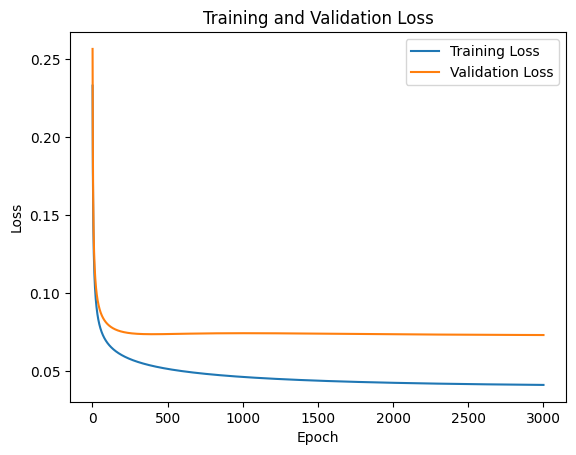

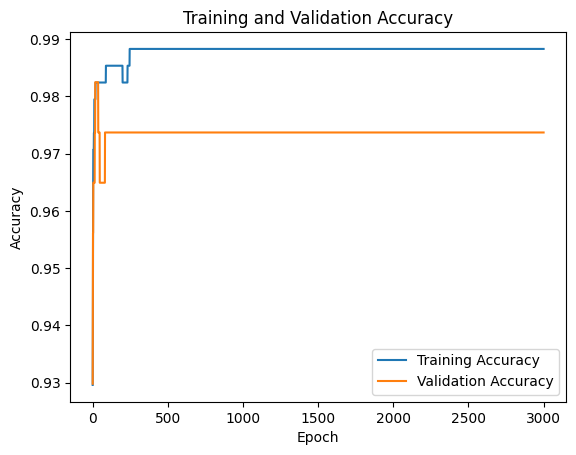

In [1321]:
import matplotlib.pyplot as plt
besthistory=oldvalues[bestlambda]
epochnumbers=np.arange(1,epochs+1)
plt.plot(epochnumbers,besthistory["trainloss"], label="Training Loss")
plt.plot(epochnumbers,besthistory["valloss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.show()

plt.plot(epochnumbers,besthistory["trainaccuracy"], label="Training Accuracy")
plt.plot(epochnumbers,besthistory["valaccuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.show()

Both training and validation losses decrease as the number of epochs increases and then they stablize (as they become nearly unchanged). This indicates that the model is learning and approaching convergence.

Training and validation accuracy increase and then they stablize (as they become nearly unchanged). The similar performance on both datasets indicates that the model generalizes well.

In [1322]:
learning_rates=[0.01,0.1,1,5,20]
lam=0.01
epochs=1000
print(f"{'Learning Rate(step size)':<17} {'Final Training Loss':<17}")

for ss in learning_rates:
    w=np.zeros(X_tr_bias.shape[1])
    for epoch in range(epochs):
        gradient=compute_gradient(X_tr_bias, y_tr,w,lam)
        w=w-ss*gradient
    finalloss=compute_data_loss(X_tr_bias, y_tr, w)
    print(f"{ss:<17} {finalloss:<17.4f}")

Learning Rate(step size) Final Training Loss
0.01              0.1052           
0.1               0.0729           
1                 0.0711           
5                 0.0711           
20                0.6493           


A small learning rate (step size=0.01) results in slower learning, while learning rates 0.1, 1 and 5 achieve lower training losses. A learning rate of 20 performs poorly, indicating that the learning rate is too large

In [1323]:
lam=0
epochs=20000
eta=0.5
w=np.zeros(X_tr_bias.shape[1])
weightnorms=[]
traininglosses=[]
for epoch in range(epochs):
    gradient=compute_gradient(X_tr_bias,y_tr,w,lam)
    w=w-eta*gradient
    weightnorms.append(np.linalg.norm(w[1:]))
    traininglosses.append(compute_data_loss(X_tr_bias,y_tr,w))
print("Final weight norm:", weightnorms[-1])
print("Final training loss:", traininglosses[-1])

Final weight norm: 19.07910409109684
Final training loss: 0.011458238949846758


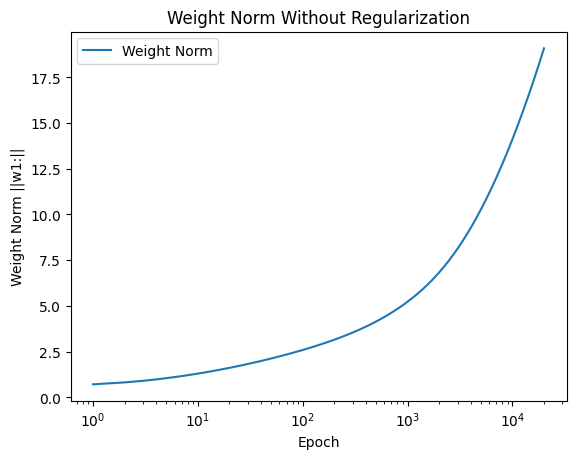

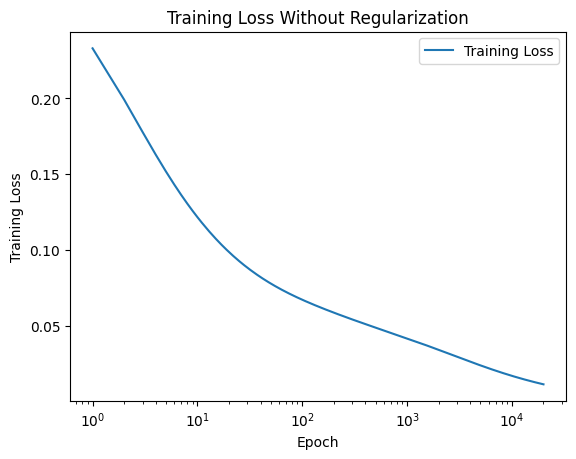

In [1324]:
epoch_numbers=np.arange(1,epochs+1)
plt.plot(epoch_numbers, weightnorms, label="Weight Norm")
plt.xlabel("Epoch")
plt.ylabel("Weight Norm ||w1:||")
plt.title("Weight Norm Without Regularization")
plt.xscale("log")
plt.legend()
plt.show()

plt.plot(epoch_numbers, traininglosses, label="Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss Without Regularization")
plt.xscale("log")
plt.legend()
plt.show()

The training set appears to be linearly separable because the weight norm keeps increasing while the training loss keeps decreasing as the number of epochs increases. This indicates that the model can continue improving the separation between the two classes by increasing the magnitude of its weights

For linearly separable data, the logistic loss can approach zero by continuously increasing the magnitude of the weights in a direction that correctly separates the classes. However, no finite weight vector achieves exactly zero loss, so the unregularized objective does not have a finite minimizer

L2 regularization adds a penalty on large weights, discouraging them from growing. This helps produce a finite solution and prevents the weights from increasing indefinitely


In [1325]:
from sklearn.linear_model import LogisticRegression
lambdas=[0,1e-3,1e-2,1e-1,1]
sklearn_results={}
sklearn_models={}
for lam in lambdas:
    if lam==0:
        model=LogisticRegression(penalty=None,max_iter=100000)
    else:
        C=1/(lam*N)
        model=LogisticRegression(C=C,penalty='l2',max_iter=100000 )
    model.fit(X_tr_std, y_tr)
    trainpred=model.predict(X_tr_std)
    valpred=model.predict(X_va_std)
    trainacc=np.mean(trainpred==y_tr)
    valacc=np.mean(valpred==y_va)
    sklearn_models[lam]=model
    sklearn_results[lam] = {"trainaccuracy": trainacc,
        "valaccuracy": valacc
    }
    print("Lambda:", lam)
    if lam==0:
        print("C:None")
    else:
        print("C:",1/(lam*N))
    print("Training accuracy:", trainacc)
    print("Validation accuracy:", valacc)
    print("\n")


Lambda: 0
C:None
Training accuracy: 1.0
Validation accuracy: 0.9649122807017544


Lambda: 0.001
C: 2.9325513196480935
Training accuracy: 0.9882697947214076
Validation accuracy: 0.9736842105263158


Lambda: 0.01
C: 0.29325513196480935
Training accuracy: 0.9853372434017595
Validation accuracy: 0.9736842105263158


Lambda: 0.1
C: 0.029325513196480937
Training accuracy: 0.9736070381231672
Validation accuracy: 0.9736842105263158


Lambda: 1
C: 0.002932551319648094
Training accuracy: 0.9384164222873901
Validation accuracy: 0.956140350877193




c:\Users\malak\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\malak\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


In [1326]:
lam=0.01
epochs=100000
eta=0.5
w=np.zeros(X_tr_bias.shape[1])
for epoch in range(epochs):
    gradient=compute_gradient( X_tr_bias,y_tr,w,lam)
    w=w-eta*gradient


In [1327]:
lam=0.01
C=1/(lam*N)
smodel=LogisticRegression(C=C,penalty='l2',tol=1e-12,max_iter=100000)
smodel.fit(X_tr_std,y_tr)
sklearn_models[0.01]=smodel


c:\Users\malak\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


In [1328]:
smodel=sklearn_models[0.01]
# Combine intercept and feature coefficients
wsklearn=np.concatenate((smodel.intercept_,smodel.coef_.ravel()))
relativeerror=np.linalg.norm(w-wsklearn)/max(np.linalg.norm(w),np.linalg.norm(wsklearn),1e-12)
print("My weights:")
print(w)
print("\nSklearn weights:")
print(wsklearn)
print("\nRelative weight error:", relativeerror)

if relativeerror<1e-4:
    print("Passed, relative error < 1e-4")
else:
    print("Failed")
print("\n")
mytestpred=(sigmoid(X_te_bias@w)>=0.5).astype(int)
sklearntestpred=smodel.predict(X_te_std)
if np.array_equal(mytestpred, sklearntestpred):
    print("Identical predictions")
else:
    print("Not identical predictions")

mytestaccuracy=np.mean(mytestpred == y_te)
sklearntestaccuracy=np.mean(sklearntestpred == y_te)
print("My Model test accuracy:",mytestaccuracy)
print("Sklearn test accuracy:",sklearntestaccuracy)


My weights:
[-0.42381639  0.45272781  0.4263065   0.43913875  0.43804957  0.29735916
 -0.02913228  0.48050766  0.6841554  -0.06778635 -0.25009878  0.51799217
  0.00371987  0.3139665   0.43284878  0.10062269 -0.37107719 -0.04554002
  0.25970856 -0.07377749 -0.40369869  0.60473948  0.89740174  0.53914397
  0.55938958  0.48909878  0.05929756  0.45633732  0.51856858  0.58966179
 -0.00755816]

Sklearn weights:
[-0.42381669  0.45272814  0.42630667  0.43913901  0.43804956  0.29735929
 -0.02913226  0.48050726  0.68415511 -0.06778639 -0.25009845  0.51799241
  0.00372002  0.31396622  0.43284867  0.10062251 -0.37107717 -0.04553991
  0.25970891 -0.07377761 -0.40369878  0.60473964  0.89740166  0.53914392
  0.55938939  0.48909906  0.05929757  0.45633758  0.51856848  0.58966202
 -0.00755869]

Relative weight error: 5.333922719263466e-07
Passed, relative error < 1e-4


Identical predictions
My Model test accuracy: 0.9824561403508771
Sklearn test accuracy: 0.9824561403508771


The gradient descent model's weights and scikit-learn's weights closely match each other with relative error less than 1e-4, and the test predictions agrees 

In [1329]:
Cvalues = [0.001, 0.01, 0.1, 1, 10, 100, 1000]
Cresults = []
for C in Cvalues:
    model = LogisticRegression(C=C,penalty='l2',max_iter=100000)
    model.fit(X_tr_std, y_tr)
    trainacc=model.score(X_tr_std, y_tr)
    valacc=model.score(X_va_std, y_va)
    testacc=model.score(X_te_std, y_te)
    Cresults.append({
        "C": C,
        "Train Accuracy": trainacc,
        "Validation Accuracy": valacc,
        "Test Accuracy": testacc
    })

print(f"{'C':<12} {'Train Acc':<12} {'Val Acc':<12} {'Test Acc':<12}")
for r in Cresults:
    print(f"{r['C']:<12}" f"{r['Train Accuracy']:<12.4f}" f"{r['Validation Accuracy']:<12.4f}" f"{r['Test Accuracy']:<12.4f}")


C            Train Acc    Val Acc      Test Acc    
0.001       0.8798      0.9035      0.8684      
0.01        0.9501      0.9649      0.9474      
0.1         0.9795      0.9825      0.9825      
1           0.9883      0.9737      0.9737      
10          0.9971      0.9649      0.9649      
100         1.0000      0.9561      0.9561      
1000        1.0000      0.9474      0.9561      


c:\Users\malak\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\malak\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


The results show that increasing the value of C, increases training accuracy because the regularization becomes weaker (lambda decrease), allowing the model to fit the training data more closely.

For C= 0.001, strong regularization may lead to underfitting, resulting in lower training, validation, and test accuracy.

The highest validation accuracy is at C=0.1, with 0.9795 training accuracy, 0.9825 validation accuracy, and 0.9825 test accuracy.

For larger values (C>=100), training accuracy continues to increase, reaching 1.0. However, validation and test accuracy decrease, which may indicate overfitting.

Therefore, C=0.1 provides the best performance among the tested values.

In [1330]:
import time
C=1/(0.01*N)
solvers=['lbfgs', 'liblinear', 'saga']
solverresults = {}
for solver in solvers:
    model=LogisticRegression(C=C,penalty='l2',solver=solver,max_iter=100000,tol=1e-12,random_state=42)
    start=time.perf_counter()
    model.fit(X_tr_std, y_tr)
    tottime=time.perf_counter()-start
    coefficients = np.concatenate((model.intercept_,model.coef_.ravel()))
    solverresults[solver]={
        "coefficients": coefficients,
        "iterations": model.n_iter_[0],
        "time": tottime
    }
print(f"{'Solver':<15} {'Iterations':<15} {'Time (s)':<15}")
for solver, result in solverresults.items():
    print(f"{solver:<15}"f"{result['iterations']:<15}"f"{result['time']:<15.6f}")
    print("Coefficients:")
    print(result["coefficients"])
    print("\n")

c:\Users\malak\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\malak\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Solver          Iterations      Time (s)       
lbfgs          29             0.009616       
Coefficients:
[-0.42381669  0.45272814  0.42630667  0.43913901  0.43804956  0.29735929
 -0.02913226  0.48050726  0.68415511 -0.06778639 -0.25009845  0.51799241
  0.00372002  0.31396622  0.43284867  0.10062251 -0.37107717 -0.04553991
  0.25970891 -0.07377761 -0.40369878  0.60473964  0.89740166  0.53914392
  0.55938939  0.48909906  0.05929757  0.45633758  0.51856848  0.58966202
 -0.00755869]


liblinear      10             0.004629       
Coefficients:
[-0.28790001  0.44114212  0.41979197  0.42895102  0.44979909  0.29007223
 -0.04430759  0.49874909  0.69566227 -0.06947058 -0.23585109  0.54909857
  0.01023401  0.3445813   0.47403964  0.11242256 -0.38386543 -0.05577167
  0.23532989 -0.0562777  -0.39408908  0.60784635  0.88201207  0.54380091
  0.58916267  0.49969386  0.05272622  0.4558991   0.5114535   0.58518838
  0.00601692]


saga           1354           0.090463       
Coefficients:
[-0.423816

The three solvers (lbfgs, liblinear, and saga) were compared using the same regularization parameter C=1/(0.01×N).Their coefficients, number of iterations, and execution times were recorded to compare their optimization performance

saga produced coefficients closest to lbfgs

liblinear converged in the fewest iterations (10)

liblinear had the shortest training time (0.002662 seconds)

Although liblinear was the fastest, its coefficients differed more from the other solvers because it penalizes the intercept, unlike lbfgs and saga.

The liblinear solver penalizes the intercept (because it represents the intercept using additional synthetic feature that is added to the input features). The coefficient of this synthetic feature represents the intercept which means the intercept is included in the regularization penalty, unlike the other two solvers. As a result, the intercept is encouraged to be closer to zero, which can affect the decision boundary

In [1331]:
# Calculate probabilities on the test set
test_probs = sigmoid(X_te_bias@w)
# Predict using threshold = 0.5
test_pred = (test_probs >= 0.5).astype(int)
cm=confusion_matrix(y_te,test_pred,2)
print("Test Confusion Matrix:")
print(cm)
# Calculate classification metrics
metrics=classification_metrics(cm)
print("Precision:",metrics["precision"][1])
print("Recall:",metrics["recall"][1])
print("F1:",metrics["f1"][1])


Test Confusion Matrix:
[[72  0]
 [ 2 40]]
Precision: 1.0
Recall: 0.9523809523809523
F1: 0.975609756097561


At a threshold of 0.5:

The model correctly classified all 72 benign cases and 40 out of 42 malignant cases

It achieved a precision of 1.0, meaning that all cases predicted as malignant were actually malignant 

The recall is 0.9524 , meaning that the model detected 95.24% of the actual malignant cases, while missing 2 cases

In [1332]:
# Calculate probabilities on the validation set
val_probs = sigmoid(X_va_bias @ w)

def roc_curve_scratch(ytrue, scores):
    sortedind = np.argsort(-scores) # np.argsort(-scores) gives us the indices that would sort the scores in descending order.
    ysorted=ytrue[sortedind]
    sortedscores=scores[sortedind]
    P=np.sum(ytrue==1) # P = total number of actual malignant patients. p=TP + FN: Total number of actual malignant cases
    N=np.sum(ytrue==0) # N = total number of actual benign patients.
    TP=0
    FP=0
    tpr=[0]
    fpr=[0]
    i = 0
    while i<len(sortedscores):
        threshold = sortedscores[i]
        # Process all samples with the same score
        while i<len(sortedscores) and sortedscores[i]==threshold:
            if ysorted[i]==1:
                TP+=1
            else:
                FP+=1
            i+=1
        tpr.append(TP/P)
        fpr.append(FP/N)

    return np.array(fpr),np.array(tpr)

In [1333]:
fpr,tpr=roc_curve_scratch(y_va, val_probs)
from sklearn.metrics import roc_auc_score
auc=np.trapezoid(tpr,fpr)
print("Scratch AUC:",auc)
sklearnauc=roc_auc_score(y_va, val_probs)
print("Sklearn AUC:", sklearnauc)
difference = abs(auc - sklearnauc)
print("Absolute difference:", difference)
if difference<1e-6:
    print("Passed, difference < 1e-6")
else:
    print("Failed, difference >= 1e-6")

Scratch AUC: 0.9957418932197839
Sklearn AUC: 0.9957418932197838
Absolute difference: 1.1102230246251565e-16
Passed, difference < 1e-6


Verfication check: The abs differnece is less than 1e-6

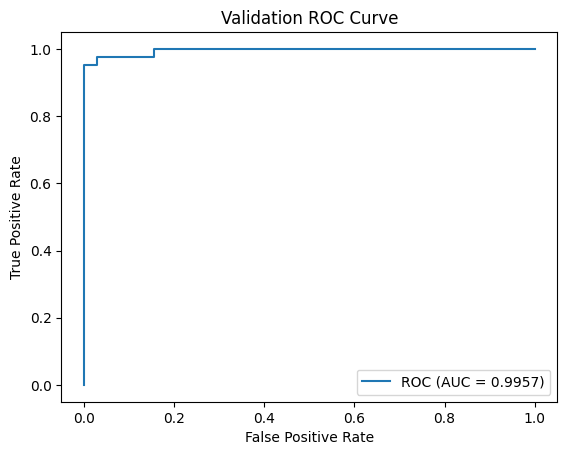

In [1334]:
plt.plot(fpr, tpr, label=f"ROC (AUC = {auc:.4f})")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Validation ROC Curve")
plt.legend()
plt.show()


The ROC curve is very close to the upperleft corner, indicating a high true positive rate and a low false positive rate. the AUC is approximately 0.9957. This indicates that the model has high ability to distinguish between malignant and benign cases across different classification thresholds

In [1335]:
malprob=val_probs[y_va==1]
largestthrshld=np.min(malprob)
print("Selected threshold:",largestthrshld)

valpredth=(val_probs>=largestthrshld).astype(int)
valcmth=confusion_matrix(y_va, valpredth, 2)
valmetricsth=classification_metrics(valcmth)
print("\nValidation Confusion Matrix:")
print(valcmth)
print("Validation Recall:", valmetricsth["recall"][1])

Selected threshold: 0.1460253243207389

Validation Confusion Matrix:
[[60 11]
 [ 0 43]]
Validation Recall: 1.0


The largest Threshold is the minimum predicted probalilty among malignant patients becuase validation recall =1 means Tp/Tp+Fn =1 so Fn should be 0, meaning all actual malginant patients should be predicted correctly. so we filter the malignant patients and see the minimum probability among them and then this is the max threshold, becuse threshold less than this meaning it wont be the largest, and bigger than this means it will not classify this patient as malignant so it will result fn

In [1336]:
# Apply the selected threshold to the test set
testpredth=(test_probs>=largestthrshld).astype(int)

cmth=confusion_matrix(y_te,testpredth,2)
metricsth=classification_metrics(cmth)
print("\nTest Confusion Matrix at the selected threshold:")
print(cmth)
print("Precision:",metricsth["precision"][1])
print("Recall:",metricsth["recall"][1])
print("F1:",metricsth["f1"][1])


Test Confusion Matrix at the selected threshold:
[[66  6]
 [ 1 41]]
Precision: 0.8723404255319149
Recall: 0.9761904761904762
F1: 0.9213483146067415


In [1337]:
print(f"{'Threshold':<15} {'Precision':<15} {'Recall':<15} {'F1':<15}")
print(f"{0.5:<15}" f"{metrics['precision'][1]:<15.4f} " f"{metrics['recall'][1]:<15.4f}"f"{metrics['f1'][1]:<15.4f}")
print(f"{largestthrshld:<15.4f} "f"{metricsth['precision'][1]:<15.4f} "f"{metricsth['recall'][1]:<15.4f} "f"{metricsth['f1'][1]:<15.4f}")

Threshold       Precision       Recall          F1             
0.5            1.0000          0.9524         0.9756         
0.1460          0.8723          0.9762          0.9213         


At threshold 0.5, precision is higher (1.0000), meaning there are no false positives, but recall is slightly lower (0.9524).

At threshold 0.1460, recall increases to 0.9762, meaning fewer malignant patients are missed, but precision decreases to 0.8723 because more benign patients are incorrectly classified as malignant.

False negative means a malginant patient was predicted as benign, its dangeroud because the patient need treatment but doesnt know yet.

False positive means a benign patient was predicted as malignant, which may lead to unnecessary follow-up tests that can cause stress and anxiety. 

False negatives are particularly costly, so achieving high recall is important.

We shoudnt completely trust this threshold becuse it is selected according to 43 positive patients (in the validation set), so it may not achieve recall=1 on unseen data

In [1338]:
X_tr_2=X_tr[:,:2]
X_va_2=X_va[:,:2]
X_te_2=X_te[:,:2]
# print("Training shape:", X_tr_2.shape)
# print("Validation shape:", X_va_2.shape)
# print("Testing shape:", X_te_2.shape)
scaler2=Standardizer()
scaler2.fit(X_tr_2)
X_tr_2_std=scaler2.transform(X_tr_2)
X_va_2_std=scaler2.transform(X_va_2)
X_te_2_std=scaler2.transform(X_te_2)
X_tr_2_bias=add_bias(X_tr_2_std)
X_va_2_bias=add_bias(X_va_2_std)
X_te_2_bias=add_bias(X_te_2_std)
# print("Training bias shape:", X_tr_2_bias.shape)
# print("Validation bias shape:", X_va_2_bias.shape)
# print("Testing bias shape:", X_te_2_bias.shape)

"Derive that the weights in the original (unstandardized) coordinates are w_j^orig = w_j/σ_j and w0^orig =
w0 − Σ_j w_j μ_j/σ_j"

The Standardize eqn
xj(std)=(xj(orig)−μj)/σj    (eqn 1)

z=w0(orig)+w1(orig)x1(orig)+w2(orig)x2(orig)   (eqn 2)
z=w0+w1x1(std)+w2x2(std)   (eqn 3)

Substitute eqn 1 in eqn 3:
z=w0+w1*((x1(orig)−μ1)/σ1)+w2*((x2(orig)−μ2)/σ2)
=w0+w1x1(orig)/σ1−w1μ1/σ1+w2x2(orig)/σ2−w2μ2/σ2

rearranging (by taking constants together)
=w0−w1μ1/σ1-w2μ2/σ2+w1x1(orig)/σ1+w2x2(orig)/σ2

compare with eqn 2
w0(orig)= w0−w1μ1/σ1-w2μ2/σ2 = w0−Σw_j*μ_j/σ_j
w1(orig)= w1/σ1
w2(orig)= w2/σ2


In [1339]:
lam=0
eta=0.5
epochs=5000
w2=np.zeros(X_tr_2_bias.shape[1])
for epoch in range(epochs):
    gradient = compute_gradient(X_tr_2_bias, y_tr, w2, lam)
    w2=w2-eta*gradient
print("New weights (standardized.):", w2)

New weights (standardized.): [-0.7271724   3.65679417  1.00987153]


The New weights (standardized) are:

bias=-0.7271724

w1=3.65679417

w2= 1.00987153

In [1340]:
w2orig=w2[1:]/scaler2.std
w0_orig=w2[0]-np.sum(w2[1:]*scaler2.mean/scaler2.std)
worig=np.concatenate(([w0_orig], w2orig))
print("original (unstandardized) weights:",worig)

original (unstandardized) weights: [-19.64344417   1.01746116   0.23190058]


original (unstandardized) weights are:

bias=-19.64344417   

w1=1.01746116  

w2=0.23190058

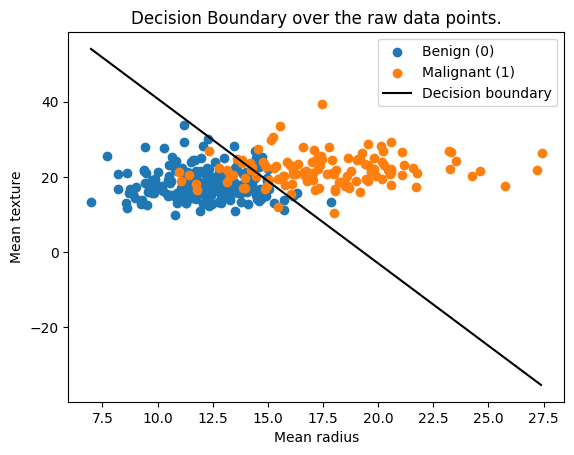

In [1341]:
# Generate x values for the line
# x_line = np.linspace(X_tr_2[:, 0].min(), X_tr_2[:, 0].max(), 200)
xline = np.arange(X_tr_2[:, 0].min(), X_tr_2[:, 0].max(), 0.1)
# Calculate corresponding y values
yline=-(worig[0]+worig[1]*xline)/worig[2]
# Plot raw data points
plt.scatter(X_tr_2[y_tr==0,0],X_tr_2[y_tr==0,1],label="Benign (0)")
plt.scatter(X_tr_2[y_tr==1,0],X_tr_2[y_tr==1,1],label="Malignant (1)")
# Plot decision boundary
plt.plot(xline, yline,label="Decision boundary",color='black')
plt.xlabel("Mean radius")
plt.ylabel("Mean texture")
plt.title("Decision Boundary over the raw data points.")
plt.legend()


The plot shows the decision line over the raw training data points as it separates the benign and malignant classes


In [1342]:
scoresstd=X_tr_2_bias@w2 # Scores using standardized features and weights
scoresorig=add_bias(X_tr_2)@worig # Scores using original features and converted weights

difference = np.max(np.abs(scoresstd-scoresorig)) # Calculate maximum absolute difference
print("Maximum score difference:", difference)
if difference<1e-9:
    print("Scores agree to 1e-9")
else:
    print("Scores do not agree to 1e-9")

Maximum score difference: 3.552713678800501e-15
Scores agree to 1e-9


We calculate the absolute difference between the two scores for each sample. Then we get the maximum(worst) among them and compare them with 1e-9

The output verifies that scores computed with the standardized and with the converted weights agree to 1e-9.
